# 13. EP3: generalización y selección (IE11 e IE12)

**IE11 (generalización).** ¿Se sostiene el resultado fuera de la muestra? Miramos la estabilidad por fold y por segmento, la calibración (¿la probabilidad dice la verdad?), un leave-one-segment-out del modelo elegido, una curva de aprendizaje por número de segmentos y la brecha entre ajuste y validación.

**IE12 (selección).** Aplicamos la regla del plan v3: entre los candidatos que cumplen O1, O3 y O4, el más simple cuyo AUC quede a menos de 0,010 del mejor. Si nadie cumple O2 ("vale la pena" frente a la regla), lo decimos igual.

**Analogía.** Elegir entre una calculadora, una hoja de cálculo y un sistema contable: si la hoja de cálculo ya da la cuenta con la precisión necesaria, no compramos el sistema contable.

Los umbrales de los puntos A (recall objetivo 0,80) y B (20 % de revisión) y el calibrador se fijan **solo** con scores internos de entrenamiento de cada fold.

In [1]:
from pathlib import Path
import json, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "conf").exists() and (p / "data").exists()), Path("C:/Users/maico/waymo-evaluacion"))
sys.path.insert(0, str(RAIZ / "src"))
REP, IMG, APP = RAIZ / "data/08_reporting_ep3", RAIZ / "images/ep3", RAIZ / "data/09_app_ep3"
IMG.mkdir(parents=True, exist_ok=True)
RECALCULAR = False          # True: vuelve a correr los scripts de esta fase (puede tardar mucho; escribe solo en *_ep3)
SEMILLA = 42
EN_MUESTRA = "en muestra: 41 segmentos, parámetros del detector ajustados con los mismos datos; post hoc, no pre-declarado; sin validación con datos nuevos"
GANANCIA_C = "La ganancia del brazo C sale de 2 celdas cámara x segmento, una de ellas en el segmento donde se descubrió el hueco."
AZUL, NARANJA, GRIS, VERDE, ROJO = "#2a78d6", "#e07b39", "#8a8a8a", "#6a994e", "#c0392b"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})

from waymo_evaluacion.ep3.plan import verificar_plan_v3
print("Plan v3 verificado (sha256):", ", ".join(verificar_plan_v3(RAIZ)))


def coma(x, d=3):
    return f"{x:.{d}f}".replace(".", ",")


def pct(x, d=1):
    return f"{100 * x:.{d}f} %".replace(".", ",")


def miles(x):
    return f"{int(round(x)):,}".replace(",", ".")


def guardar_fig(fig, nombre):
    fig.savefig(IMG / f"{nombre}.png", dpi=130, bbox_inches="tight")


def correr(script, *args):
    r = subprocess.run([sys.executable, "-X", "utf8", str(RAIZ / "scripts/ep3" / script), *args], capture_output=True, text=True, cwd=RAIZ)
    print(r.stdout[-1500:], r.stderr[-800:])
    assert r.returncode == 0, f"{script} fallo"

Plan v3 verificado (sha256): plan_v3.md, plan_v3.json


In [2]:
if RECALCULAR:
    correr("f5_generalizacion.py"); correr("f6_seleccion.py"); correr("f5_loso_curva.py")
m5 = pd.read_csv(REP / "f5_metricas_candidatos.csv")
sel = json.loads((REP / "f6_seleccion.json").read_text(encoding="utf-8"))
elegido = sel["elegido"]
cols = ["candidato", "AUC", "PR-AUC", "Captura@20", "Fraccion_80", "recall_A", "precision_A", "recall_B", "precision_B", "ECE_cal", "Brier_cal", "AUC_min_fold", "AUC_mediana_segmento", "estable"]
display(m5[cols].round(3))
print("Candidato elegido por la regla del plan:", elegido)

,candidato,AUC,PR-AUC,Captura@20,Fraccion_80,recall_A,precision_A,recall_B,precision_B,ECE_cal,Brier_cal,AUC_min_fold,AUC_mediana_segmento,estable
0,Regla top,0.823,0.672,0.619,0.446,0.798,0.376,0.629,0.641,0.044,0.112,0.647,0.898,False
1,LR3,0.808,0.660,0.608,0.468,0.810,0.363,0.614,0.659,0.060,0.114,0.651,0.908,False
2,LR,0.797,0.650,0.589,0.467,0.820,0.328,0.595,0.636,0.053,0.117,0.641,0.901,False
3,RF,0.798,0.650,0.575,0.472,0.806,0.343,0.589,0.611,0.071,0.124,0.668,0.880,False
4,HGB,0.794,0.636,0.564,0.494,0.832,0.299,0.584,0.592,0.046,0.121,0.645,0.867,False
5,XGB,0.800,0.677,0.609,0.488,0.801,0.328,0.613,0.659,0.039,0.111,0.685,0.880,False
6,LGBM,0.794,0.675,0.611,0.531,0.819,0.308,0.616,0.661,0.045,0.111,0.682,0.872,False
7,E1,0.803,0.666,0.581,0.462,0.812,0.343,0.597,0.616,0.044,0.115,0.649,0.890,False
8,E2,0.824,0.696,0.619,0.421,0.809,0.379,0.619,0.658,0.069,0.119,0.648,0.900,False
9,E3,0.789,0.662,0.604,0.523,0.803,0.342,0.618,0.641,0.037,0.112,0.664,0.875,False


Candidato elegido por la regla del plan: Regla top


## Estabilidad: AUC por fold y por segmento
Criterio del plan: AUC mínimo por fold >= 0,75 y mediana del AUC por segmento >= 0,80.

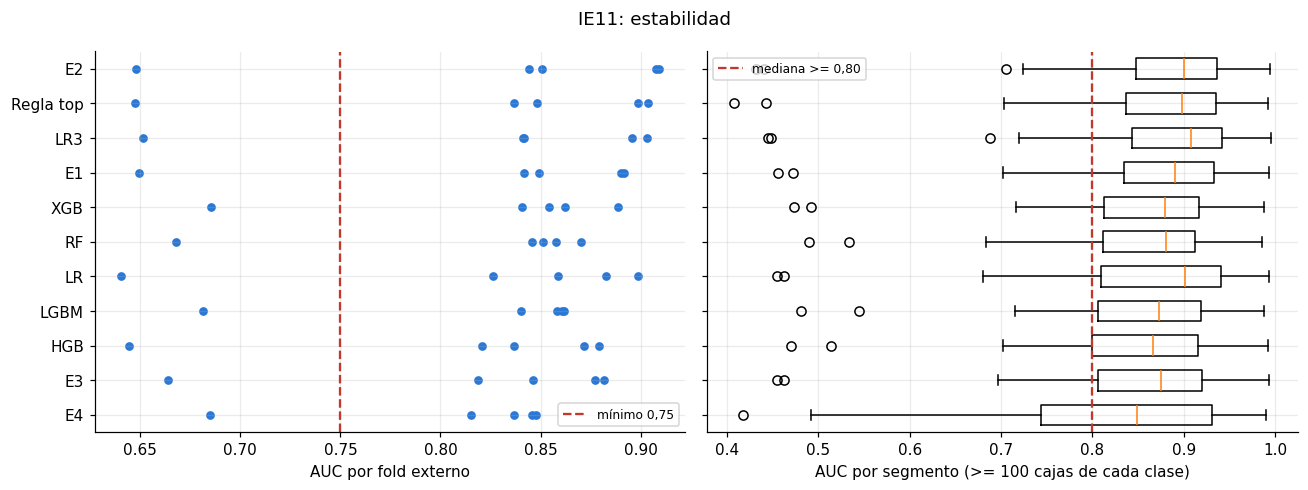

**Lectura (generada).** No cumplen el criterio de estabilidad: Regla top, LR3, LR, RF, HGB, XGB, LGBM, E1, E2, E3, E4. Un fold con pocos segmentos y una tasa distinta mueve mucho el AUC: por eso se reporta el mínimo y no solo el promedio.

In [3]:
af = pd.read_csv(REP / "f5_auc_por_fold.csv")
asg = pd.read_csv(REP / "f5_auc_por_segmento.csv")
orden = m5.sort_values("AUC")["candidato"].tolist()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for i, c in enumerate(orden):
    d = af[af["candidato"] == c]["AUC"]
    axes[0].scatter(d, [i] * len(d), color=AZUL, s=22)
    s = asg[asg["candidato"] == c]["AUC"]
    axes[1].boxplot(s, positions=[i], vert=False, widths=0.6, showfliers=True)
axes[0].axvline(0.75, color=ROJO, ls="--", label="mínimo 0,75"); axes[1].axvline(0.80, color=ROJO, ls="--", label="mediana >= 0,80")
axes[0].set_yticks(range(len(orden)), orden); axes[0].set_xlabel("AUC por fold externo"); axes[1].set_xlabel("AUC por segmento (>= 100 cajas de cada clase)")
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8); fig.suptitle("IE11: estabilidad"); fig.tight_layout(); guardar_fig(fig, "13_estabilidad"); plt.show()
inest = m5[~m5["estable"].astype(bool)]["candidato"].tolist()
display(Markdown(f"**Lectura (generada).** No cumplen el criterio de estabilidad: {', '.join(inest) if inest else 'ninguno'}. "
                 f"Un fold con pocos segmentos y una tasa distinta mueve mucho el AUC: por eso se reporta el mínimo y no solo el promedio."))

## Calibración (Platt, ajustada con scores internos de entrenamiento)
Una probabilidad calibrada dice 'de cada 100 cajas con 30 %, unas 30 son positivas'.

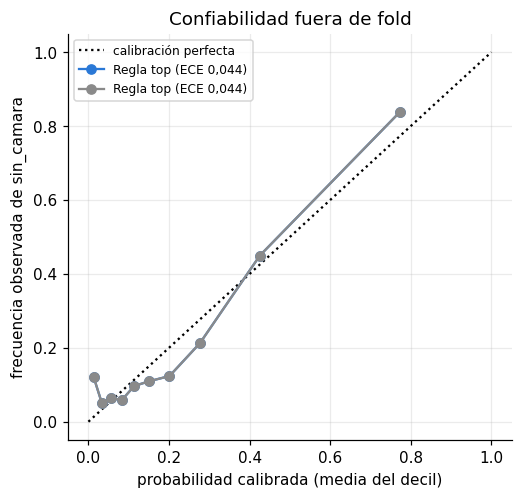

In [4]:
cb = pd.read_csv(REP / "f5_calibracion_bins.csv")
fig, ax = plt.subplots(figsize=(5.2, 4.8))
ax.plot([0, 1], [0, 1], "k:", label="calibración perfecta")
for c, col in ((elegido, AZUL), ("Regla top", GRIS)):
    d = cb[cb["candidato"] == c]
    e = m5.set_index("candidato").loc[c, "ECE_cal"]
    ax.plot(d["pred"], d["obs"], "o-", color=col, label=f"{c} (ECE {coma(e)})")
ax.set_xlabel("probabilidad calibrada (media del decil)"); ax.set_ylabel("frecuencia observada de sin_camara"); ax.legend(fontsize=8); ax.set_title("Confiabilidad fuera de fold")
guardar_fig(fig, "13_calibracion"); plt.show()

## Leave-one-segment-out, curva de aprendizaje y brecha
Se calculan para el candidato elegido y, como complemento, para los dos mejores modelos que **aprenden** (LR3 y XGBoost): si el elegido es una regla, no hay nada que aprender y su curva es plana por construcción.

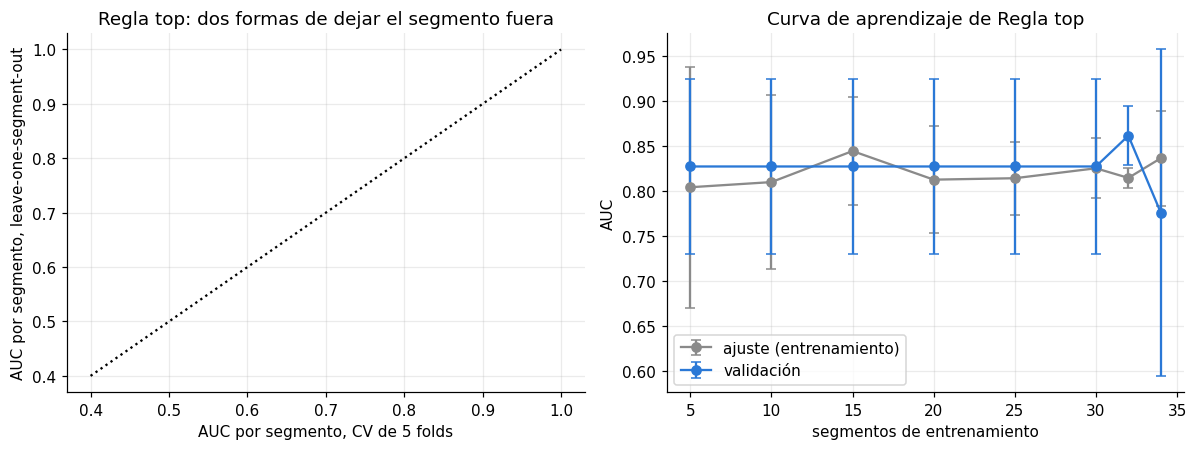

**Regla top (lectura generada).** AUC global LOSO 0,823 (IC 0,725 a 0,900); mediana por segmento 0,898; mínimo por segmento 0,408; 2 de 22 segmentos evaluables con AUC < 0,55. Brecha ajuste - validación con todos los segmentos de entrenamiento: 0,060 de AUC; la validación pasa de 0,827 con 5 segmentos a 0,776 con 34. **Una regla no aprende nada**: la curva es plana por construcción y las diferencias entre filas vienen de qué segmentos entran en cada submuestra, no de aprender (las dos últimas filas son el entrenamiento completo de folds con 32 y 34 segmentos). Con 41 segmentos y pocos folds estas curvas son ruidosas.

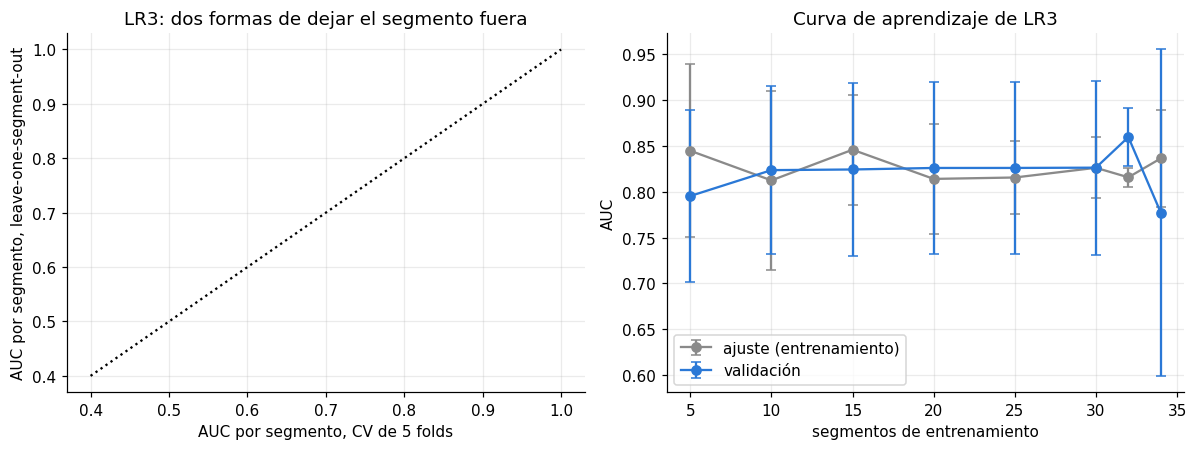

**LR3 (lectura generada).** AUC global LOSO 0,812 (IC 0,707 a 0,898); mediana por segmento 0,905; mínimo por segmento 0,433; 2 de 22 segmentos evaluables con AUC < 0,55. Brecha ajuste - validación con todos los segmentos de entrenamiento: 0,059 de AUC; la validación pasa de 0,795 con 5 segmentos a 0,777 con 34. Con 41 segmentos y pocos folds estas curvas son ruidosas.

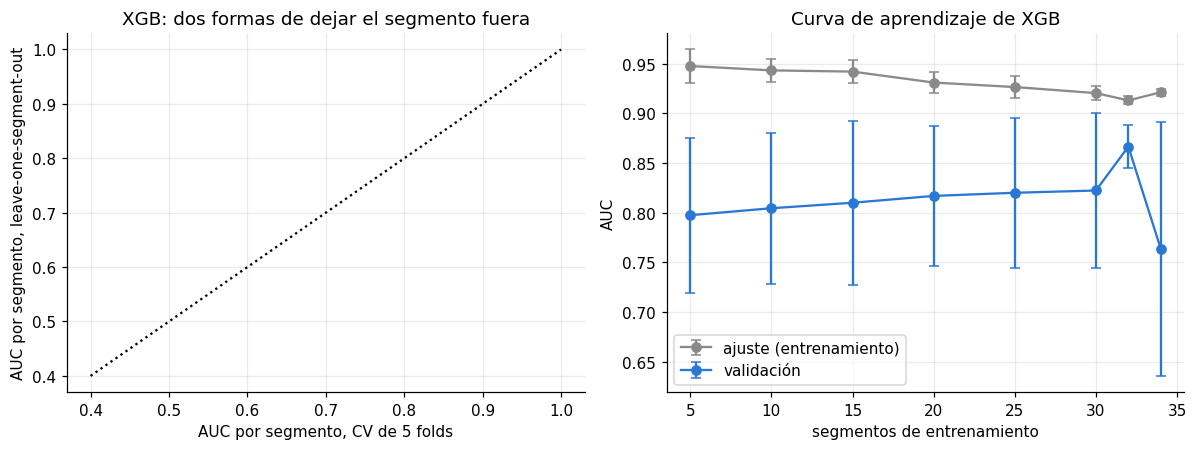

**XGB (lectura generada).** AUC global LOSO 0,802 (IC 0,710 a 0,879); mediana por segmento 0,876; mínimo por segmento 0,495; 2 de 22 segmentos evaluables con AUC < 0,55. Brecha ajuste - validación con todos los segmentos de entrenamiento: 0,158 de AUC; la validación pasa de 0,797 con 5 segmentos a 0,763 con 34. Con 41 segmentos y pocos folds estas curvas son ruidosas.

In [5]:
def sufijo(c):
    return "_" + c.replace(" ", "_")
asg_idx = asg.set_index(["candidato", "segmento"])["AUC"]
for cand in dict.fromkeys([elegido, "LR3", "XGB"]):
    f_res = REP / f"f5_loso_resumen{sufijo(cand)}.json"
    if not f_res.exists():
        print(f"{cand}: LOSO aún no calculado (scripts/ep3/f5_loso_curva.py --candidato '{cand}')"); continue
    rs = json.loads(f_res.read_text(encoding="utf-8"))
    lo = pd.read_csv(REP / f"f5_loso_segmentos{sufijo(cand)}.csv", dtype={"seg": str}).set_index("seg")
    oof = asg[asg["candidato"] == cand].set_index("segmento")["AUC"]
    comun = oof.index.intersection(lo.index)
    cur = pd.read_csv(REP / f"f5_curva_aprendizaje{sufijo(cand)}.csv")
    g = cur.groupby("n_segmentos")[["AUC_ajuste", "AUC_validacion"]].agg(["mean", "std"])
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    axes[0].scatter(oof[comun], lo.loc[comun, "AUC"], color=AZUL, s=26); axes[0].plot([0.4, 1], [0.4, 1], "k:")
    axes[0].set_xlabel("AUC por segmento, CV de 5 folds"); axes[0].set_ylabel("AUC por segmento, leave-one-segment-out"); axes[0].set_title(f"{cand}: dos formas de dejar el segmento fuera")
    for c, col, nom in (("AUC_ajuste", GRIS, "ajuste (entrenamiento)"), ("AUC_validacion", AZUL, "validación")):
        axes[1].errorbar(g.index, g[(c, "mean")], yerr=g[(c, "std")].fillna(0), fmt="o-", color=col, capsize=3, label=nom)
    axes[1].set_xlabel("segmentos de entrenamiento"); axes[1].set_ylabel("AUC"); axes[1].legend(); axes[1].set_title(f"Curva de aprendizaje de {cand}")
    fig.tight_layout(); guardar_fig(fig, f"13_loso_curva_{cand.replace(' ', '_')}"); plt.show()
    br = pd.read_csv(REP / f"f5_brecha{sufijo(cand)}.csv")
    ult = br.iloc[-1]
    display(Markdown(f"**{cand} (lectura generada).** AUC global LOSO {coma(rs['AUC'])} (IC {coma(rs['AUC_ic'][0])} a {coma(rs['AUC_ic'][1])}); mediana por segmento {coma(rs['AUC_mediana_segmento'])}; "
                     f"mínimo por segmento {coma(rs['AUC_min_segmento'])}; {rs['segmentos_con_AUC_menor_a_0_55']} de {rs['segmentos_evaluables']} segmentos evaluables con AUC < 0,55. "
                     f"Brecha ajuste - validación con todos los segmentos de entrenamiento: {coma(ult['brecha_AUC'])} de AUC; la validación pasa de {coma(br.iloc[0]['AUC_validacion'])} con {int(br.iloc[0]['n_segmentos'])} segmentos "
                     f"a {coma(ult['AUC_validacion'])} con {int(ult['n_segmentos'])}. "
                     + ("**Una regla no aprende nada**: la curva es plana por construcción y las diferencias entre filas vienen de qué segmentos entran en cada submuestra, no de aprender (las dos últimas filas son el entrenamiento completo de folds con 32 y 34 segmentos). " if cand == "Regla top" else "")
                     + "Con 41 segmentos y pocos folds estas curvas son ruidosas."))

## IE12: tabla de selección (objetivos O1 a O4)

In [6]:
ts = pd.read_csv(REP / "f6_tabla_seleccion.csv")
v = ts[["candidato", "AUC", "PR-AUC_menos_prevalencia", "Fraccion_80", "recall_A", "ECE_cal", "estable"]].copy()
for o in ("O1", "O2", "O3", "O4"):
    v[o] = np.where(ts[o], "cumple", "no")
v["dif. Fracción 80 % vs regla (IC)"] = [f"{coma(r.dif_Fraccion_80_vs_regla)} ({coma(r.dif_Fraccion_80_lo)} a {coma(r.dif_Fraccion_80_hi)})" for r in ts.itertuples()]
display(v.round(3))
display(Markdown(f"**Regla de elección (plan v3):** {sel['razon']}. **Elegido: {elegido}.** {'(La regla de reserva DEV-2 se declaró después de ver que nadie cumple O4; es post hoc, no pre-declarada.) ' if sel.get('fallback_O4') else ''}"
                 f"{'Algún candidato cumple O2: ' + ', '.join(sel['candidatos_que_cumplen_O2']) + '.' if sel['O2_lo_cumple_alguien'] else 'Ningún candidato cumple O2 (vale la pena frente a la regla): se recomienda igualmente el más simple que cumple lo demás.'}"))
esc = pd.read_csv(REP / "f6_modelo_escogido.csv").iloc[0]
cuadro = pd.DataFrame({"medida": ["AUC", "PR-AUC", "Captura al revisar 20 %", "Fracción de cajas para 80 % de recall", "Recall en el punto A", "Precisión en el punto A", "Recall en el punto B (20 %)", "Precisión en el punto B",
                                  "ECE (Platt)", "Brier (Platt)", "AUC mínimo por fold", "Mediana del AUC por segmento", "F1 en A (solo referencia)", "Accuracy en A (solo referencia)"],
                       "valor": [coma(esc[k]) for k in ["AUC", "PR-AUC", "Captura@20", "Fraccion_80", "recall_A", "precision_A", "recall_B", "precision_B", "ECE_cal", "Brier_cal", "AUC_min_fold", "AUC_mediana_segmento", "F1_A", "accuracy_A"]]})
cuadro["IC 95 % por segmentos"] = ["(%s a %s)" % (coma(esc[k + "_lo"]), coma(esc[k + "_hi"])) if k + "_lo" in esc.index else "" for k in ["AUC", "PR-AUC", "Captura@20", "Fraccion_80", "recall_A", "precision_A", "recall_B", "precision_B", "ECE_cal", "Brier_cal", "AUC_min_fold", "AUC_mediana_segmento", "F1_A", "accuracy_A"]]
display(Markdown(f"### Cuadro «Modelo escogido»: {elegido}")); display(cuadro)
display(Markdown("Accuracy y F1 son solo referencia: con una clase minoritaria de ~21 %, un clasificador trivial ya tiene accuracy alto, y no deciden nada en el plan."))

,candidato,AUC,PR-AUC_menos_prevalencia,Fraccion_80,recall_A,ECE_cal,estable,O1,O2,O3,O4,dif. Fracción 80 % vs regla (IC)
0,Regla top,0.823,0.460,0.446,0.798,0.044,False,cumple,no,cumple,no,"0,000 (0,000 a 0,000)"
1,LR3,0.808,0.448,0.468,0.810,0.060,False,cumple,no,cumple,no,"0,021 (-0,008 a 0,064)"
2,LR,0.797,0.437,0.467,0.820,0.053,False,cumple,no,cumple,no,"0,020 (-0,038 a 0,112)"
3,RF,0.798,0.438,0.472,0.806,0.071,False,cumple,no,cumple,no,"0,026 (-0,029 a 0,085)"
4,HGB,0.794,0.424,0.494,0.832,0.046,False,cumple,no,cumple,no,"0,048 (-0,011 a 0,078)"
5,XGB,0.800,0.465,0.488,0.801,0.039,False,cumple,no,cumple,no,"0,042 (-0,022 a 0,105)"
6,LGBM,0.794,0.462,0.531,0.819,0.045,False,cumple,no,cumple,no,"0,084 (-0,006 a 0,136)"
7,E1,0.803,0.453,0.462,0.812,0.044,False,cumple,no,cumple,no,"0,016 (-0,032 a 0,062)"
8,E2,0.824,0.484,0.421,0.809,0.069,False,cumple,no,cumple,no,"-0,025 (-0,048 a 0,008)"
9,E3,0.789,0.450,0.523,0.803,0.037,False,cumple,no,cumple,no,"0,077 (0,012 a 0,128)"


**Regla de elección (plan v3):** ningún candidato cumple O4 (regla de reserva DEV-2); entre los 11 candidatos que cumplen O1 y O3, el mejor AUC OOF es 0,824; los que quedan a menos de 0,010 son Regla top, E2; el más simple es Regla top. **Elegido: Regla top.** (La regla de reserva DEV-2 se declaró después de ver que nadie cumple O4; es post hoc, no pre-declarada.) Ningún candidato cumple O2 (vale la pena frente a la regla): se recomienda igualmente el más simple que cumple lo demás.

### Cuadro «Modelo escogido»: Regla top

,medida,valor,IC 95 % por segmentos
0,AUC,"0,823","(0,725 a 0,900)"
1,PR-AUC,"0,672","(0,558 a 0,769)"
2,Captura al revisar 20 %,"0,619","(0,533 a 0,723)"
3,Fracción de cajas para 80 % de recall,"0,446","(0,279 a 0,704)"
4,Recall en el punto A,"0,798","(0,676 a 0,900)"
5,Precisión en el punto A,"0,376",
6,Recall en el punto B (20 %),"0,629","(0,535 a 0,728)"
7,Precisión en el punto B,"0,641",
8,ECE (Platt),"0,044",
9,Brier (Platt),"0,112",


Accuracy y F1 son solo referencia: con una clase minoritaria de ~21 %, un clasificador trivial ya tiene accuracy alto, y no deciden nada en el plan.

## Sobre la elección: E2 y la regla

In [7]:
t6 = pd.read_csv(REP / "f6_tabla_seleccion.csv").set_index("candidato"); m5i = m5.set_index("candidato")
e2 = m5i.loc["E2"]; rg = m5i.loc["Regla top"]
display(Markdown(f"**E2** (promedio de rangos de E1 y la regla) tiene AUC {coma(e2['AUC'])} contra {coma(rg['AUC'])} de la regla, PR-AUC {coma(e2['PR-AUC'])} contra {coma(rg['PR-AUC'])}, Fracción para 80 % {coma(e2['Fraccion_80'])} contra {coma(rg['Fraccion_80'])} "
                 f"(IC de la diferencia {coma(t6.loc['E2', 'dif_Fraccion_80_lo'])} a {coma(t6.loc['E2', 'dif_Fraccion_80_hi'])}) y ECE {coma(e2['ECE_cal'])} (> 0,05); además **contiene a la regla**. No hay diferencia distinguible y la elección de la regla se hizo por simplicidad, como manda el plan. "
                 "**Ningún candidato supera a la regla de forma distinguible.**"))

**E2** (promedio de rangos de E1 y la regla) tiene AUC 0,824 contra 0,823 de la regla, PR-AUC 0,696 contra 0,672, Fracción para 80 % 0,421 contra 0,446 (IC de la diferencia -0,048 a 0,008) y ECE 0,069 (> 0,05); además **contiene a la regla**. No hay diferencia distinguible y la elección de la regla se hizo por simplicidad, como manda el plan. **Ningún candidato supera a la regla de forma distinguible.**

## Análisis en muestra (post hoc, no pre-declarado; fase 12.1): ¿qué pasa en el fold 0?
*(en muestra: 41 segmentos, parámetros del detector ajustados con los mismos datos; post hoc, no pre-declarado; sin validación con datos nuevos)*

In [8]:
if RECALCULAR:
    correr("f12_analisis_muestra.py")
f12 = pd.read_csv(REP / "f12_auc_por_fold_brazos.csv"); r12 = json.loads((REP / "f12_resumen.json").read_text(encoding="utf-8"))
reg = f12[f12["candidato"] == "Regla top"]
display(reg[["fold", "segmentos", "cajas", "celdas_con_hueco", "hueco_contenido", "AUC_A", "AUC_B_celdas_sanas", "Fraccion80_A", "Fraccion80_B_celdas_sanas", "Fraccion80_C"]].round(3))
d12 = pd.read_csv(REP / "f12_diferencia_C_menos_A.csv"); dr = d12[(d12["candidato"] == "Regla top")]
display(dr[["variante", "Fraccion80_A", "Fraccion80_C", "dif_C_menos_A", "ic_lo", "ic_hi", "excluye_0", "segmentos"]].round(3))
g = dr[dr["variante"].str.startswith("global")].iloc[0]
display(Markdown(f"**¿El brazo B cumple AUC mínimo por fold >= 0,75?** Sí: {coma(r12['B_AUC_min_fold']['Regla top'])} (regla); el brazo A no ({coma(r12['A_AUC_min_fold']['Regla top'])}): el fallo del fold 0 se debe a la celda con hueco. "
                 f"**¿Qué hace C en el fold 1?** Baja la Fracción para 80 % de {coma(r12['C_en_fold_1_regla']['Fraccion80_A'])} a {coma(r12['C_en_fold_1_regla']['Fraccion80_C'])}. "
                 f"**¿El IC de C menos A excluye 0?** No: {coma(g['dif_C_menos_A'])} con IC {coma(g['ic_lo'])} a {coma(g['ic_hi'])}; {pct(g['prop_replicas_C_mejor'])} de las réplicas favorece a C y el resto no contiene ningún segmento con hueco. {GANANCIA_C}"))

,fold,segmentos,cajas,celdas_con_hueco,hueco_contenido,AUC_A,AUC_B_celdas_sanas,Fraccion80_A,Fraccion80_B_celdas_sanas,Fraccion80_C
0,0,7,14968,1,257766998801 camara 3,0.647,0.842,0.805,0.466,0.236
1,1,9,14971,1,911012534050 camara 5,0.837,0.919,0.315,0.193,0.174
2,2,9,14950,0,ninguno,0.848,0.848,0.378,0.378,0.378
3,3,7,15659,0,ninguno,0.904,0.904,0.343,0.343,0.343
4,4,9,20023,0,ninguno,0.899,0.899,0.287,0.287,0.287
5,global,41,80571,2,911012534050 camara 5; 257766998801 camara 3,0.823,0.879,0.446,0.337,0.296


,variante,Fraccion80_A,Fraccion80_C,dif_C_menos_A,ic_lo,ic_hi,excluye_0,segmentos
0,global: ambas celdas auditadas,0.446,0.296,-0.150,-0.490,0.0,False,41
1,solo se audita 911012534050 camara 5 (la otra ...,0.446,0.425,-0.021,-0.091,0.0,False,41
2,se excluye el segmento 911012534050 del analis...,0.434,0.305,-0.129,-0.436,0.0,False,40
3,solo se audita 257766998801 camara 3 (la otra ...,0.446,0.319,-0.127,-0.465,0.0,False,41
4,se excluye el segmento 257766998801 del analis...,0.354,0.333,-0.021,-0.095,0.0,False,40


**¿El brazo B cumple AUC mínimo por fold >= 0,75?** Sí: 0,842 (regla); el brazo A no (0,647): el fallo del fold 0 se debe a la celda con hueco. **¿Qué hace C en el fold 1?** Baja la Fracción para 80 % de 0,315 a 0,174. **¿El IC de C menos A excluye 0?** No: -0,150 con IC -0,490 a 0,000; 88,1 % de las réplicas favorece a C y el resto no contiene ningún segmento con hueco. La ganancia del brazo C sale de 2 celdas cámara x segmento, una de ellas en el segmento donde se descubrió el hueco.

## Equidad descriptiva (post hoc; fase 12.3)
Regla en el punto A por ubicación, momento del día y clase, con y sin las celdas con hueco; AUC solo con >= 200 cajas en cada clase. Sin pruebas de hipótesis.

In [9]:
eq = pd.read_csv(REP / "f12_equidad.csv")
display(eq[["variable", "grupo", "celdas_con_hueco", "segmentos", "cajas", "positivos", "recall_A", "pct_revisado_A", "AUC"]].round(3))
cic = eq[(eq["grupo"] == "CYCLIST") & (eq["celdas_con_hueco"] == "incluidas")].iloc[0]
display(Markdown(f"**Lectura (generada).** El recall de la regla en A en ciclistas es {coma(cic['recall_A'])} con solo {int(cic['positivos'])} positivos; parte de las brechas por momento del día y ubicación se achica al quitar las celdas con hueco."))

,variable,grupo,celdas_con_hueco,segmentos,cajas,positivos,recall_A,pct_revisado_A,AUC
0,ubicacion,location_other,incluidas,7,6089,798,0.944,0.372,0.943
1,ubicacion,location_other,excluidas,7,6089,798,0.944,0.372,0.943
2,ubicacion,location_phx,incluidas,18,12800,2132,0.915,0.527,0.867
3,ubicacion,location_phx,excluidas,18,12800,2132,0.915,0.527,0.867
4,ubicacion,location_sf,incluidas,16,61682,14172,0.779,0.445,0.811
5,ubicacion,location_sf,excluidas,16,59737,12607,0.866,0.457,0.878
6,momento_del_dia,Dawn/Dusk,incluidas,11,15617,3061,0.790,0.452,0.825
7,momento_del_dia,Dawn/Dusk,excluidas,11,15617,3061,0.790,0.452,0.825
8,momento_del_dia,Day,incluidas,18,41586,8224,0.760,0.474,0.773
9,momento_del_dia,Day,excluidas,18,39641,6659,0.920,0.494,0.900


**Lectura (generada).** El recall de la regla en A en ciclistas es 0,443 con solo 115 positivos; parte de las brechas por momento del día y ubicación se achica al quitar las celdas con hueco.